# 07 | 車站周邊的自行車可及性

1.	在投影座標系統下做環域（buffer）與距離計算，並能確認單位是公尺。
2.	用環域計數與最近鄰連接（sjoin_nearest）描述車站的自行車轉乘可及性。
3.	決定「什麼算一個車站」，處理共站、重複列出與不是車站的資料。
4.	說明直線距離的限制。

## 0. 路徑與中文字型

沿用 `00_Colab環境設定範本.ipynb` 的兩個儲存格。本週多了三個路徑：鄉鎮市區界、老師的備援快照，以及你自己從 TDX 抓下來的資料。

In [1]:
import sys
import urllib.request
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib import font_manager

"""路徑設定"""
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/115-1_GISprog")

    """安裝相關套件"""
    %pip install -q mapclassify
else:
    # 備援：本機執行時，notebook 位於 115-1_GISprog/notebooks/，上一層就是專案資料夾
    PROJECT_DIR = Path.cwd().parent

"""字型設定"""
FONT_DIR = PROJECT_DIR / "fonts"
FONT_URL = "https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download"
FONT_PATH = FONT_DIR / "TaipeiSansTCBeta-Regular.ttf"

if not FONT_PATH.exists():
    FONT_DIR.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(FONT_URL, FONT_PATH)

font_manager.fontManager.addfont(str(FONT_PATH))     # 告訴 Matplotlib：「這個字型檔可以使用」
plt.rcParams["font.family"] = "Taipei Sans TC Beta"  # 指定之後畫圖預設使用這個中文字型
plt.rcParams["axes.unicode_minus"] = False           # 避免負號 − 顯示異常
print("已設定中文字型：", FONT_PATH.name)

已設定中文字型： TaipeiSansTCBeta-Regular.ttf


## 1. 選縣市、準備資料

* 選一個縣市。建議沿用 HW6 的縣市：HW6 存在 data/raw/tdx/ 的站點快照可以直接讀取，不必再呼叫站點 API。請在筆記註明快照的日期。
    * 臺中市是課堂範例，請選其他縣市。 HW6 選臺中市的同學，HW7 請換一個縣市。
    * 嘉義市只有 2 個臺鐵車站，不建議選。
* 確認雲端硬碟的 `115-1_GISprog/data/raw/` 已有 `Taiwan_boundaries`、`tdx_station_20261012`，以及本週的 `tdx_rail_20261023`。
* 在 `notebooks/` 建立 `07_rail_bike_access.ipynb`。可以請 agent 參考課堂的 `07_空間分析與可及性.ipynb` 撰寫，但每一步的結果都要自己檢查。


In [2]:
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"


TOWN_SHP = RAW_DIR / "Taiwan_boundaries" / "Town" / "Taiwan_town.shp"  # 鄉鎮市區界
BIKE_BACKUP = RAW_DIR / "tdx_station_20261012"                         # W6 的站點備援快照
RAIL_BACKUP = RAW_DIR / "tdx_rail_20261023"                            # 本週的軌道車站備援快照
TDX_DIR = RAW_DIR / "tdx"                                              # 你自己從 TDX 抓的資料

for p in [TOWN_SHP, BIKE_BACKUP, RAIL_BACKUP]:
    if not p.exists():
        raise FileNotFoundError(f"找不到 {p}，請依課前準備上傳課堂資料")

print("執行環境：", "Google Colab" if IN_COLAB else "本機", sep="") 
print("預備檔案：Taiwan_boundaries、tdx_station_20261012、tdx_rail_20261023 資料夾讀取成功")

CITY = "NewTaipei" 
CITY_DICT = {
                "Taipei": "臺北市", "NewTaipei": "新北市", "Taoyuan": "桃園市", "Taichung": "臺中市", "Tainan": "臺南市",
                "Kaohsiung": "高雄市", "Hsinchu": "新竹市", "HsinchuCounty": "新竹縣", "MiaoliCounty": "苗栗縣", "ChanghuaCounty": "彰化縣",
                "YunlinCounty": "雲林縣", "ChiayiCounty": "嘉義縣", "Chiayi": "嘉義市", "PingtungCounty": "屏東縣", "TaitungCounty": "臺東縣"
            }     

if CITY_DICT.get(CITY) == None:
    raise ValueError("CITY 的值錯誤，請確認選擇的程式代號是否輸入正確")
else:
    print("所選縣市：" + str(CITY_DICT.get(CITY)))

執行環境：本機
預備檔案：Taiwan_boundaries、tdx_station_20261012、tdx_rail_20261023 資料夾讀取成功
所選縣市：新北市


## 2. 取得軌道車站

* 臺鐵： `/v3/Rail/TRA/Station`，全國一次取得。v3 的回傳是 dict，車站清單在 "Stations" 裡。
* 高鐵： `/v2/Rail/THSR/Station`，全國一次取得。你的縣市沒有高鐵站的話可以省略。
* 捷運、輕軌、纜車： `/v2/Rail/Metro/Station/{代碼}`。代碼見課堂 notebook A4，例如 TRTC（臺北捷運）、TYMC（桃園機場捷運）、KRTC（高雄捷運）。
* 臺鐵沒有縣市欄位：用 sjoin 和鄉鎮市區界判斷車站所在縣市，篩出你的縣市。捷運也一樣，系統不等於縣市（桃園機場捷運有站在臺北市、新北市）。
* 每份資料都存快照：檔案已存在就讀檔，不再呼叫 API。

新北市要呼叫 7 次以上（臺鐵、高鐵、5 個捷運與輕軌系統），會超過基礎會員「每把金鑰每分鐘 5 次」的限制。分成兩格、隔一分鐘再執行，或在每次呼叫之間 time.sleep(15)。

In [3]:
import os
import json
import time
import requests
import pandas as pd
import geopandas as gpd

from datetime import datetime
from zoneinfo import ZoneInfo
from dotenv import load_dotenv


"""讀取環境變數"""
if IN_COLAB:
    from google.colab import userdata
    for k in ["TDX_CLIENT_ID", "TDX_CLIENT_SECRET"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception as e:  # 沒設定密鑰，或沒打開 Notebook access
            print(f"讀不到 {k}：{type(e).__name__}")

    HAS_KEY = all(os.environ.get(k) for k in ["TDX_CLIENT_ID", "TDX_CLIENT_SECRET"])

else:
    HAS_KEY = load_dotenv()

print("金鑰狀態：", "TDX 金鑰已載入" if HAS_KEY else "沒有 TDX 金鑰，Part C 將改讀老師的備援快照", sep="")


AUTH_URL = "https://tdx.transportdata.tw/auth/realms/TDXConnect/protocol/openid-connect/token"
API_BASE = "https://tdx.transportdata.tw/api/basic"

_token = {"value": None, "expires": 0}
call_record = []   # 本次執行的紀錄：api（呼叫 API）、token（換 token）、cache（讀快照，沒連 TDX）
CALL_LOG = TDX_DIR / "call_log.csv"   # 真的連到 TDX 的呼叫會累計寫入，重開 kernel 也不會歸零


"""記一筆紀錄；真的連到 TDX 的（api、token）另外附加到 call_log.csv"""
def log_call(kind, path, status=None):
    rec = {"time": datetime.now(ZoneInfo("Asia/Taipei")).strftime("%Y-%m-%d %H:%M:%S"),
           "type": kind, "path": path, "status": status}
    call_record.append(rec)
    if kind != "cache":
        TDX_DIR.mkdir(parents=True, exist_ok=True)
        pd.DataFrame([rec]).to_csv(CALL_LOG, mode="a", header=not CALL_LOG.exists(),
                                   index=False, encoding="utf-8-sig")


"""回傳 access token；還沒過期就沿用（token 快取）。"""
def get_token():
    if _token["value"] and time.time() < _token["expires"] - 60:
        return _token["value"]
    r = requests.post(AUTH_URL, data={
        "grant_type": "client_credentials",
        "client_id": os.environ["TDX_CLIENT_ID"],
        "client_secret": os.environ["TDX_CLIENT_SECRET"],
    }, timeout=30)
    log_call("token", "/auth/token", r.status_code)
    r.raise_for_status()
    data = r.json()
    _token["value"] = data["access_token"]
    _token["expires"] = time.time() + data["expires_in"]
    return _token["value"]


"""呼叫 TDX 基礎服務，回傳解析後的 JSON。"""
def get_json(path, params=None):
    headers = {"authorization": f"Bearer {get_token()}", "Accept-Encoding": "gzip"}
    r = requests.get(API_BASE + path, headers=headers,
                     params={"$format": "JSON", **(params or {})}, timeout=30)
    log_call("api", path, r.status_code)
    r.raise_for_status()
    return r.json()

"""取得軌道車站(今天抓過就讀檔；有金鑰才呼叫 API 並存檔；都沒有就讀老師的備援快照。)"""
today = datetime.now(ZoneInfo("Asia/Taipei")).strftime("%Y%m%d")

def read_data(path, name, saving):
    snap = TDX_DIR / f"{name}_{today}.json"
    output = "快照狀態："

    if snap.exists():
        log_call("cache", path, snap.name)      # 讀今天已存的快照，沒有連 TDX（只記在本次紀錄，不寫入 call_log.csv）
        output += "讀取今天已存的快照 " + str(snap.name)
        print(output)
        return json.loads(snap.read_text(encoding="utf-8"))
    if HAS_KEY:
        data = get_json(path)
        TDX_DIR.mkdir(parents=True, exist_ok=True)
        time.sleep(15)
        snap.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
        output += "已從 TDX 取得並存檔 " + str(snap.name)
        print(output)
        return data

    log_call("cache", path, saving.name)        # 讀老師的備援快照，也沒有連 TDX
    output += "改讀老師的備援快照 " + str(saving.name)
    print(output)
    return json.loads(saving.read_text(encoding="utf-8"))

track = {
    "TRA":      read_data("/v3/Rail/TRA/Station", "rail_TRA", RAIL_BACKUP / "rail_TRA.json"),
    "THSR":     read_data("/v2/Rail/THSR/Station", "rail_THSR", RAIL_BACKUP / "rail_THSR.json"),
    "TRTC":     read_data("/v2/Rail/Metro/Station/TRTC", "metro_TRTC", RAIL_BACKUP / "metro_TRTC.json") if CITY == "Taipei" or CITY == "NewTaipei" else None,
    "TRTCMG":   read_data("/v2/Rail/Metro/Station/TRTCMG", "metro_TRTCMG", RAIL_BACKUP / "metro_TRTCMG.json") if CITY == "Taipei" else None,
    "NTMC":     read_data("/v2/Rail/Metro/Station/NTMC", "metro_NTMC", RAIL_BACKUP / "metro_NTMC.json") if CITY == "NewTaipei" else None,
    "NTDLRT":   read_data("/v2/Rail/Metro/Station/NTDLRT", "metro_NTDLRT", RAIL_BACKUP / "metro_NTDLRT.json") if CITY == "NewTaipei" else None,
    "NTALRT":   read_data("/v2/Rail/Metro/Station/NTALRT", "metro_NTALRT", RAIL_BACKUP / "metro_NTALRT.json") if CITY == "NewTaipei" else None,
    "TYMC":     read_data("/v2/Rail/Metro/Station/TYMC", "metro_TYMC", RAIL_BACKUP / "metro_TYMC.json") if CITY == "Taipei" or CITY == "NewTaipei" or CITY == "Taoyuan" else None,
    "TMRT":     read_data("/v2/Rail/Metro/Station/TMRT", "metro_TMRT", RAIL_BACKUP / "metro_TMRT.json") if CITY == "Taichung" else None,
    "KRTC":     read_data("/v2/Rail/Metro/Station/KRTC", "metro_KRTC", RAIL_BACKUP / "metro_KRTC.json") if CITY == "Kaohsiung" else None,
    "KLRT":     read_data("/v2/Rail/Metro/Station/KLRT", "metro_KLRT", RAIL_BACKUP / "metro_KLRT.json") if CITY == "Kaohsiung" else None
}

track_station = {
    "TRA":      "臺灣鐵路",
    "THSR":     "台灣高鐵",
    "TRTC":     "臺北捷運",
    "TRTCMG":   "貓空纜車",
    "NTMC":     "新北捷運（環狀線、三鶯線）",
    "NTDLRT":   "淡海輕軌",
    "NTALRT":   "安坑輕軌",
    "TYMC":     "桃園機場捷運",
    "TMRT":     "臺中捷運",
    "KRTC":     "高雄捷運",
    "KLRT":     "高雄輕軌"
}

track_output = []
for i in track:
    if track.get(i) != None:
        track_output.append(track_station.get(i))

print("\n所選縣市之軌道車站：" + "、".join(track_output))

金鑰狀態：TDX 金鑰已載入
快照狀態：讀取今天已存的快照 rail_TRA_20261103.json
快照狀態：讀取今天已存的快照 rail_THSR_20261103.json
快照狀態：讀取今天已存的快照 metro_TRTC_20261103.json
快照狀態：讀取今天已存的快照 metro_NTMC_20261103.json
快照狀態：讀取今天已存的快照 metro_NTDLRT_20261103.json
快照狀態：讀取今天已存的快照 metro_NTALRT_20261103.json
快照狀態：讀取今天已存的快照 metro_TYMC_20261103.json

所選縣市之軌道車站：臺灣鐵路、台灣高鐵、臺北捷運、新北捷運（環狀線、三鶯線）、淡海輕軌、安坑輕軌、桃園機場捷運


## 3. 環域計數
* 車站與站點都轉成 EPSG:3826。印出 CRS 的單位，並用一個環域的面積反推半徑，確認單位是公尺。
* 對每個車站做 300 公尺與 500 公尺環域，計算範圍內的 YouBike 站點數。
* 環域內沒有站點的車站也要列出來，記為 0。 驗證：計數表的列數等於車站數。


In [4]:
bike = read_data(f"/v2/Bike/Station/City/{CITY}", f"station_{CITY}", BIKE_BACKUP / f"station_{CITY}.json")

"""把 TDX 車站清單轉成 GeoDataFrame（EPSG:4326），只留系統、代碼、站名。"""
def change_point(rows, system):
    df = pd.json_normalize(rows)
    return gpd.GeoDataFrame(
        {"系統": system, "StationUID": df["StationUID"], "站名": df["StationName.Zh_tw"]},
        geometry=gpd.points_from_xy(df["StationPosition.PositionLon"], df["StationPosition.PositionLat"]),
        crs="EPSG:4326",
    )

"""每個軌道系統各轉成一張 GeoDataFrame，放進 list"""
frame = []
for system, data in track.items():      # system 是系統代碼（如 "TRA"），data 是該系統的車站資料
    if data is None:                     # 所選縣市沒有這個系統，跳過
        continue

    stations = data["Stations"] if isinstance(data, dict) else data   # 臺鐵 v3 回傳 dict，車站在 "Stations" 裡
    frame.append(change_point(stations, system))

"""用 concat 把所有系統接成一張表，車站與站點都轉成 EPSG:3826"""
rail = gpd.GeoDataFrame(pd.concat(frame, ignore_index=True), crs="EPSG:4326").to_crs(3826)
bike = change_point(bike, "YouBike").to_crs(3826)

print("車站", rail.crs)
print("站點", bike.crs)
print("各系統車站數（全國，尚未篩縣市）：")
print(rail["系統"].value_counts())
print("\n========================================")

"""用鄉鎮市區界判斷每個車站所在的縣市（臺鐵、捷運都沒有可靠的縣市欄位，所以用空間位置判斷）"""
town = gpd.read_file(TOWN_SHP)
rail = rail.to_crs(town.crs)   # 確保兩邊 CRS 相同（EPSG:3826）

rail = gpd.sjoin(rail, town[["COUNTYNAME", "TOWNNAME", "geometry"]],
                 how="left", predicate="within").drop(columns="index_right")
print("\n沒有配對到鄉鎮的車站：", rail["COUNTYNAME"].isna().sum())

"""統一「台」與「臺」的寫法，避免比對時漏掉"""
rail["COUNTYNAME"] = rail["COUNTYNAME"].str.replace("台", "臺")
city_name = CITY_DICT[CITY].replace("台", "臺")

"""篩出所選縣市的車站"""
rail_city = rail[rail["COUNTYNAME"] == city_name].reset_index(drop=True)
print(f"{city_name}共 {len(rail_city)} 筆車站資料")
display(rail_city.groupby("系統")["站名"].agg(["count", "、".join]))


快照狀態：讀取今天已存的快照 station_NewTaipei_20261103.json
車站 EPSG:3826
站點 EPSG:3826
各系統車站數（全國，尚未篩縣市）：
系統
TRA       245
TRTC      122
NTMC       26
TYMC       22
NTDLRT     14
THSR       12
NTALRT      9
Name: count, dtype: int64



c:\Users\s1112\anaconda3\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()



沒有配對到鄉鎮的車站： 0
新北市共 115 筆車站資料


,count,join
系統,,
NTALRT,9,雙城、玫瑰中國城、台北小城、耕莘安康院區、景文科大、安康、陽光運動公園、新和國小、十四張
NTDLRT,14,紅樹林、竿蓁林、淡金鄧公、淡江大學、淡金北新、新市一路、淡水行政中心、濱海義山、濱海沙崙、淡...
NTMC,26,頂埔、媽祖田、長壽山、橫溪、龍埔、三峽、台北大學、鶯歌車站、陶瓷老街、國華、永吉公園、鶯桃福...
THSR,1,板橋
TRA,24,五堵、汐止、汐科、板橋、浮洲、樹林、南樹林、山佳、鶯歌、鳳鳴、福隆、貢寮、雙溪、牡丹、三貂嶺...
TRTC,35,頂埔、永寧、土城、海山、亞東醫院、府中、板橋、新埔、江子翠、新店、新店區公所、七張、大坪林、...
TYMC,6,三重站、新北產業園區站、新莊副都心站、泰山站、泰山貴和站、林口站


### 什麼算「一個車站」

決策（寫進決策表）：

1. **不是車站的資料要刪除：** 名稱含「基地」「-」「機廠」「號誌」的資料，例如課堂看到的臺鐵「臺北-環島」（環島列車代碼）、「潮州基地」（車輛基地）。
2. **共站合併成一站：** 不同系統、相距 350 公尺內的車站視為同一個轉乘站，例如板橋（臺鐵、高鐵、北捷、新北捷運）、新埔／新埔民生（322 公尺）。350 公尺是看過實際資料後決定的：轉乘站最遠的新埔／新埔民生相距 322 公尺，不是轉乘站的丹鳳／泰山貴和相距 459 公尺。
3. **同一系統的車站不合併：** 同一條線上的前後站不會是同一站。距離太近的會列出來，到地圖上人工確認座標。
4. 合併後的位置取各筆的中心點，站名去掉結尾的「站」「車站」，系統用「、」串起來。


In [5]:
"""什麼算「一個車站」：先刪掉不是車站的資料，再把共站合併成一站"""
import networkx as nx

rail_city_raw = rail_city.copy()   # 保留合併前的原始清單，最後一起輸出到 GPKG
print(f"合併前：{len(rail_city_raw)} 筆")

"""1. 不是車站的資料：名稱含「基地」「-」「機廠」「號誌」"""
not_station = rail_city["站名"].str.contains("基地|-|機廠|號誌")
print("名稱看起來不是車站、刪除的資料：", rail_city.loc[not_station, ["系統", "站名"]].values.tolist())
rail_city = rail_city[~not_station].reset_index(drop=True)

"""2. 找出彼此相距 JOIN_M 公尺內的車站配對（點落在另一站的環域內）"""
JOIN_M = 350
area = rail_city[["系統", "geometry"]].copy()
area["geometry"] = rail_city.buffer(JOIN_M)
pairs = gpd.sjoin(rail_city[["系統", "geometry"]], area, predicate="within")
pairs = pairs[pairs.index != pairs["index_right"]]          # 去掉「自己配自己」

"""同一系統卻靠得很近的：不合併，列出來人工檢查座標"""
same_system = pairs[(pairs["系統_left"] == pairs["系統_right"]) & (pairs.index < pairs["index_right"])]
for a, b in zip(same_system.index, same_system["index_right"]):
    d = rail_city.geometry[a].distance(rail_city.geometry[b])
    print(f"⚠ 同一系統卻只相距 {d:.0f} 公尺（不合併，請到地圖上確認座標）：",
          rail_city.loc[a, "系統"], rail_city.loc[a, "站名"], "／", rail_city.loc[b, "站名"])

"""不同系統的配對才是轉乘站"""
pairs = pairs[pairs["系統_left"] != pairs["系統_right"]]

"""3. 用 networkx 找「連在一起」的群組：A 配 B、B 配 C，A、B、C 就是同一站（例如板橋有 4 筆）"""
G = nx.Graph()
G.add_nodes_from(rail_city.index)
G.add_edges_from(zip(pairs.index, pairs["index_right"]))
rail_city["車站編號"] = 0
for group_id, members in enumerate(nx.connected_components(G)):
    rail_city.loc[list(members), "車站編號"] = group_id

"""4. 依車站編號合併：站名去掉結尾的「站」「車站」，系統和代碼用「、」串起來，位置取中心點"""
rail_city["站名"] = rail_city["站名"].str.replace(r"(車站|站)$", "", regex=True)
merged = rail_city.dissolve(by="車站編號", aggfunc={
    "系統": lambda s: "、".join(s),
    "StationUID": lambda s: "、".join(s),
    "站名": lambda s: "／".join(s.unique()),
})
merged["合併筆數"] = rail_city.groupby("車站編號").size()
merged["geometry"] = merged.centroid

"""中心點可能跨到隔壁鄉鎮，重新判斷所在的鄉鎮"""
merged = gpd.sjoin(merged.reset_index(drop=True), town[["COUNTYNAME", "TOWNNAME", "geometry"]],
                   how="left", predicate="within").drop(columns="index_right")
rail_city = merged.reset_index(drop=True)

print(f"\n合併後：{len(rail_city)} 個車站（{(rail_city['合併筆數'] > 1).sum()} 個是共站）")
display(rail_city[rail_city["合併筆數"] > 1][["站名", "系統", "合併筆數", "TOWNNAME"]].sort_values("合併筆數", ascending=False))


合併前：115 筆
名稱看起來不是車站、刪除的資料： []
⚠ 同一系統卻只相距 13 公尺（不合併，請到地圖上確認座標）： NTALRT 台北小城 ／ 耕莘安康院區

合併後：102 個車站（11 個是共站）


,站名,系統,合併筆數,TOWNNAME
3,板橋,TRA、THSR、TRTC、NTMC,4,板橋區
8,鶯歌,TRA、NTMC,2,鶯歌區
24,頂埔,TRTC、NTMC,2,土城區
30,新埔／新埔民生,TRTC、NTMC,2,板橋區
35,大坪林,TRTC、NTMC,2,新店區
38,景安,TRTC、NTMC,2,中和區
43,三重,TRTC、TYMC,2,三重區
45,頭前庄,TRTC、NTMC,2,新莊區
56,紅樹林,TRTC、NTDLRT,2,淡水區
68,十四張,NTMC、NTALRT,2,新店區


In [6]:
"""回傳每個車站周圍「公尺」範圍內的站點數；沒有站點的車站記為 0。"""
def buffer_count(station, point, meter):
    area = station[["geometry"]].copy()
    area["geometry"] = station.buffer(meter)
    connect = gpd.sjoin(point[["geometry"]], area, predicate="within")
    return connect.groupby("index_right").size().reindex(station.index, fill_value=0)


"""計算車站環域內的 YouBike 站點數（第二個參數是要被計數的點：bike）"""
rail_city["300m站點數"] = buffer_count(rail_city, bike, 300)
rail_city["500m站點數"] = buffer_count(rail_city, bike, 500)

print("\n500 公尺內沒有站點的車站：", (rail_city["500m站點數"] == 0).sum(), "站")
print("300 公尺內沒有站點的車站：", (rail_city["300m站點數"] == 0).sum(), "站")
display(rail_city.sort_values("300m站點數")[["系統", "站名", "TOWNNAME", "300m站點數", "500m站點數"]].head(8))



500 公尺內沒有站點的車站： 6 站
300 公尺內沒有站點的車站： 7 站


,系統,站名,TOWNNAME,300m站點數,500m站點數
19,TRA,平溪,平溪區,0,1
17,TRA,望古,平溪區,0,0
16,TRA,十分,平溪區,0,0
15,TRA,大華,平溪區,0,0
14,TRA,三貂嶺,瑞芳區,0,0
23,TRA,四腳亭,瑞芳區,0,0
10,TRA,福隆,貢寮區,0,0
21,TRA,猴硐,瑞芳區,1,1


## 4. 最近站點的距離
* 用 `sjoin_nearest`（加上 `distance_col`）計算每個車站到最近 YouBike 站點的距離。
* 檢查連接後的筆數是否等於車站數。一樣近的站點會讓同一個車站出現兩列，要處理後再對應回車站。
* 用另一種方法交叉驗證，例如 max_distance=500 找出的車站，和步驟三「500 公尺內 0 站」的車站是否相同。


In [7]:
"""每個車站找最近的 YouBike 站點；右邊的「站名」先改名成「最近站點」，避免和左邊的「站名」撞名"""
nearest = gpd.sjoin_nearest(
    rail_city[["系統", "站名", "geometry"]],
    bike[["站名", "geometry"]].rename(columns={"站名": "最近站點"}),
    how="left",
    distance_col="最近距離_m",
)

print("車站數：", len(rail_city), "→ 連接後：", len(nearest))
print("重複出現的車站：", nearest.index.duplicated().sum())

"""距離一樣近時，同一個車站會對到多個站點；每個車站只留一筆再對應回 rail_city"""
rail_city["最近距離_m"] = nearest.groupby(level=0)["最近距離_m"].min().round(0)
rail_city["最近站點"] = nearest.groupby(level=0)["最近站點"].first()

"""交叉驗證"""
in_500 = gpd.sjoin_nearest(rail_city[["站名", "geometry"]], bike[["站名", "geometry"]],how="left", max_distance=500)
print("500 公尺內找不到站點的車站：", in_500["站名_right"].isna().sum(), "站")
print("雙方驗證結果：", (rail_city["500m站點數"] == 0).sum() == in_500["站名_right"].isna().sum())

display(rail_city.sort_values("最近距離_m", ascending=False)[["系統", "站名", "TOWNNAME", "最近站點", "最近距離_m"]].head(5))


車站數： 102 → 連接後： 102
重複出現的車站： 0
500 公尺內找不到站點的車站： 6 站
雙方驗證結果： True


,系統,站名,TOWNNAME,最近站點,最近距離_m
23,TRA,四腳亭,瑞芳區,YouBike2.0_瑞芳火車站,4538.0
10,TRA,福隆,貢寮區,YouBike2.0_龍門運動公園,1830.0
17,TRA,望古,平溪區,YouBike2.0_嶺腳車站,1649.0
15,TRA,大華,平溪區,YouBike2.0_十分遊客中心,1500.0
16,TRA,十分,平溪區,YouBike2.0_十分遊客中心,1019.0


## 5. 可及性最差的車站與地圖
* 列出 500 公尺內沒有 YouBike 站點的車站。
    * 如果你的縣市每個車站都有： 改列出最近距離最遠的 5 個車站，或 300 公尺內車柱數（BikesCapacity）最少的 5 個車站，並在決策表說明 500 公尺這個門檻在你的縣市是否合適。彰化縣、雲林縣的 Moovo 沒有 BikesCapacity，請用站點數。
* 畫地圖：車站依可及性分級著色（例如 500 公尺內 0 站、1–2 站、3 站以上），疊上 YouBike 站點；要有中文標題與圖例。
* 用 `explore()` 疊在臺灣通用電子地圖上目視檢查：挑 2–3 個可及性最差的車站，看看最近的站點走得到嗎？中間有沒有鐵路、河川或快速道路？
* 輸出 GPKG 到 `data/processed/`，至少包含車站圖層（含 300、500 公尺站點數與最近距離）。


In [8]:
"""列出 500 公尺內沒有 YouBike 站點的車站"""
no_bike = rail_city[rail_city["500m站點數"] == 0]
cols = ["系統", "站名", "TOWNNAME", "最近站點", "最近距離_m"]

if len(no_bike) == 0:
    print("每個車站 500 公尺內都有 YouBike，列出距離最遠的 5 站：")
    display(rail_city.sort_values("最近距離_m", ascending=False)[cols].head(5))
else:
    print(f"500 公尺內沒有 YouBike 的車站共 {len(no_bike)} 站：")
    display(no_bike.sort_values("最近距離_m", ascending=False)[cols])

500 公尺內沒有 YouBike 的車站共 6 站：


,系統,站名,TOWNNAME,最近站點,最近距離_m
23,TRA,四腳亭,瑞芳區,YouBike2.0_瑞芳火車站,4538.0
10,TRA,福隆,貢寮區,YouBike2.0_龍門運動公園,1830.0
17,TRA,望古,平溪區,YouBike2.0_嶺腳車站,1649.0
15,TRA,大華,平溪區,YouBike2.0_十分遊客中心,1500.0
16,TRA,十分,平溪區,YouBike2.0_十分遊客中心,1019.0
14,TRA,三貂嶺,瑞芳區,YouBike2.0_三貂嶺隧道(金字橋),513.0


可及性分級
0 站       6
1–2 站    20
3 站以上    76
Name: count, dtype: int64


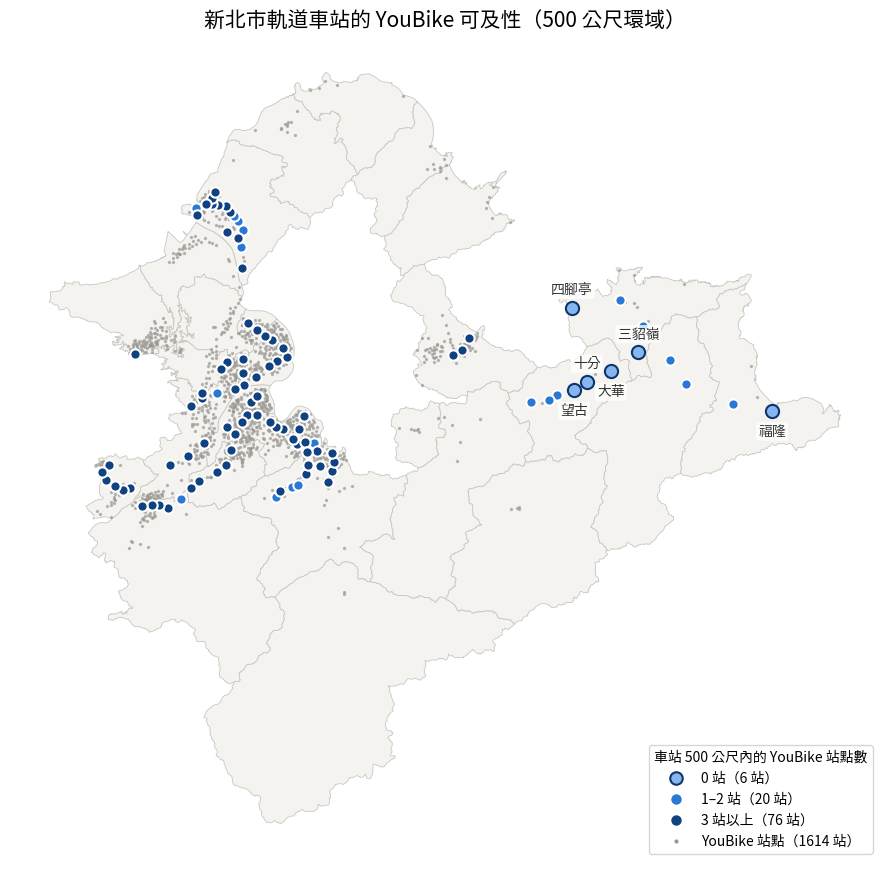

In [9]:
"""畫地圖：車站依 500 公尺內的 YouBike 站點數分級著色，疊上 YouBike 站點"""
from matplotlib.lines import Line2D

"""依 500 公尺內的 YouBike 站點數分成三級"""
LEVELS = ["0 站", "1–2 站", "3 站以上"]
COLORS = ["#86b6ef", "#2a78d6", "#104281"]   # 同一色相由淺到深：站點越多顏色越深

rail_city["可及性分級"] = pd.cut(rail_city["500m站點數"], bins=[-1, 0, 2, float("inf")], labels=LEVELS)
print(rail_city["可及性分級"].value_counts().reindex(LEVELS))

"""底圖：所選縣市的鄉鎮市區界"""
town_city = town[town["COUNTYNAME"].str.replace("台", "臺") == city_name]

fig, ax = plt.subplots(figsize=(9, 10))
town_city.plot(ax=ax, color="#f4f3f0", edgecolor="#c9c7c2", linewidth=0.6)

"""YouBike 站點：小灰點，當作背景參考"""
bike.plot(ax=ax, color="#9a9893", markersize=2, alpha=0.6)

"""軌道車站：依分級著色；「0 站」是重點，加深色外框並畫大一點"""
EDGES = ["#0d366b", "white", "white"]
SIZES = [90, 55, 55]
for level, color, edge, size in zip(LEVELS, COLORS, EDGES, SIZES):
    rail_city[rail_city["可及性分級"] == level].plot(
        ax=ax, color=color, markersize=size, edgecolor=edge, linewidth=1.5, zorder=3)

"""500 公尺內 0 站的車站直接標上站名；由西到東排序，標籤上下交錯避免重疊"""
zero = rail_city[rail_city["可及性分級"] == "0 站"].copy()
zero["x"] = zero.geometry.x
zero = zero.sort_values("x")
for i, (_, row) in enumerate(zero.iterrows()):
    ax.annotate(row["站名"], xy=(row.geometry.x, row.geometry.y),
                xytext=(0, 10) if i % 2 == 0 else (0, -18), textcoords="offset points",
                ha="center", fontsize=10, color="#333333",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))

"""圖例：手動建立，數量寫在括號裡"""
counts = rail_city["可及性分級"].value_counts()
handles = [Line2D([], [], marker="o", linestyle="", markersize=9, markerfacecolor=c,
                  markeredgecolor=e, markeredgewidth=1.5, label=f"{lv}（{counts[lv]} 站）")
           for lv, c, e in zip(LEVELS, COLORS, EDGES)]
handles.append(Line2D([], [], marker="o", linestyle="", markersize=3,
                      markerfacecolor="#9a9893", markeredgecolor="none", label=f"YouBike 站點（{len(bike)} 站）"))
ax.legend(handles=handles, title="車站 500 公尺內的 YouBike 站點數", loc="lower right", frameon=True, fontsize=10, title_fontsize=10)

ax.set_title(f"{city_name}軌道車站的 YouBike 可及性（500 公尺環域）", fontsize=15)
ax.set_axis_off()
plt.tight_layout()

"""存到 outputs/"""
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_DIR / f"07_車站可及性分級_{CITY}.png", dpi=200, bbox_inches="tight")
plt.show()


In [10]:
"""用 explore() 疊在臺灣通用電子地圖上，目視檢查可及性最差的車站"""
import folium

# 臺灣通用電子地圖（內政部國土測繪中心 WMTS）；注意網址是 {z}/{y}/{x}
map_web = "https://wmts.nlsc.gov.tw/wmts/EMAP/default/GoogleMapsCompatible/{z}/{y}/{x}"
map_from = "臺灣通用電子地圖 © 內政部國土測繪中心"

"""第一層：縣市內的鄉鎮界（只畫框線，當作參考）"""
m = town_city.explore(
    color="#888888", style_kwds={"fill": False, "weight": 1},
    tooltip=["TOWNNAME"], tiles=map_web, attr=map_from, name="鄉鎮市區界")

"""第二層：500 公尺內沒有 YouBike 的車站，畫出 500 公尺環域，方便看最近的站點離圈外多遠"""
worst = rail_city[rail_city["可及性分級"] == "0 站"].copy()
worst["geometry"] = worst.buffer(500)
worst[["站名", "最近站點", "最近距離_m", "geometry"]].explore(
    m=m, color="#0d366b", style_kwds={"fillOpacity": 0.1, "weight": 2, "dashArray": "5, 5"},
    tooltip=["站名", "最近站點", "最近距離_m"], name="0 站車站的 500 公尺環域")

"""第三層：YouBike 站點（灰色小點）"""
bike[["站名", "StationUID", "geometry"]].explore(
    m=m, color="#666666", marker_kwds={"radius": 3}, tooltip=["站名", "StationUID"], name="YouBike 站點")

"""第四層：軌道車站，依可及性分級著色（顏色和上面的靜態地圖一致）"""
rail_city[["系統", "站名", "TOWNNAME", "300m站點數", "500m站點數", "最近站點", "最近距離_m", "可及性分級", "geometry"]].explore(
    m=m, column="可及性分級", categorical=True, cmap=COLORS,
    marker_kwds={"radius": 7}, style_kwds={"color": "white", "weight": 1.5, "fillOpacity": 1},
    tooltip=["系統", "站名", "TOWNNAME", "500m站點數", "最近站點", "最近距離_m"],
    legend=True, legend_kwds={"caption": "500 公尺內 YouBike 站點數"}, name="軌道車站")

folium.LayerControl().add_to(m)   # 右上角可以開關各圖層
m


## 6. 各鄉鎮的環域覆蓋比例
把 500 公尺環域 dissolve 成一個面，再和你的縣市的鄉鎮市區 overlay，計算各鄉鎮被車站 500 公尺範圍覆蓋的面積比例。比較「直接把環域面積相加」與「dissolve 後的面積」差多少，並說明原因。


In [11]:
"""比較：每個車站 500 公尺環域的面積直接相加 vs. dissolve 成一個面後的面積"""
import math

station_buffer = rail_city[["系統", "站名", "geometry"]].copy()
station_buffer["geometry"] = rail_city.buffer(500)

"""方法一：直接把每個環域的面積相加（重疊的地方會被算好幾次）"""
area_sum = station_buffer.area.sum() / 1e6          # 平方公尺 → 平方公里

"""方法二：dissolve 成一個面再算面積（重疊的地方只算一次）"""
buffer_union = station_buffer[["geometry"]].dissolve()   # 沒有指定 by，全部合併成一個面
area_union = buffer_union.area.sum() / 1e6

print(f"車站數（合併共站後）：{len(station_buffer)}")
print(f"一個 500 公尺環域的理論面積 π×500²：{math.pi * 500**2 / 1e6:.4f} 平方公里")
print(f"實際一個環域的面積：{station_buffer.area.iloc[0] / 1e6:.4f} 平方公里（buffer 是用多邊形近似圓，所以略小）")
print(f"方法一 直接相加：{area_sum:.2f} 平方公里")
print(f"方法二 dissolve：{area_union:.2f} 平方公里")
print(f"相差：{area_sum - area_union:.2f} 平方公里（重複計算的部分占相加結果的 {(area_sum - area_union) / area_sum:.1%}）")

"""找原因一：共站。如果沒有先合併共站，同一個轉乘站的好幾個環域會幾乎整個疊在一起"""
area_sum_raw = rail_city_raw.buffer(500).area.sum() / 1e6
print(f"\n若不合併共站（{len(rail_city_raw)} 筆）直接相加：{area_sum_raw:.2f} 平方公里，"
      f"比合併後多 {area_sum_raw - area_sum:.2f} 平方公里")

"""找原因二：兩站相距不到 1000 公尺，兩個 500 公尺環域就會部分重疊"""
nearest_station = gpd.sjoin_nearest(rail_city[["站名", "geometry"]], rail_city[["站名", "geometry"]],
                                    distance_col="距離_m", exclusive=True)
close = nearest_station.groupby(level=0)["距離_m"].min()
print(f"最近的另一個車站在 1000 公尺內的車站：{(close < 1000).sum()} 站，占 {(close < 1000).mean():.0%}")


車站數（合併共站後）：102
一個 500 公尺環域的理論面積 π×500²：0.7854 平方公里
實際一個環域的面積：0.7841 平方公里（buffer 是用多邊形近似圓，所以略小）
方法一 直接相加：79.98 平方公里
方法二 dissolve：74.27 平方公里
相差：5.72 平方公里（重複計算的部分占相加結果的 7.1%）

若不合併共站（115 筆）直接相加：90.18 平方公里，比合併後多 10.19 平方公里
最近的另一個車站在 1000 公尺內的車站：65 站，占 64%


In [12]:
"""把 dissolve 後的環域和鄉鎮市區 overlay，計算各鄉鎮被車站 500 公尺範圍覆蓋的面積比例"""
town_area = town_city[["TOWNNAME", "geometry"]].copy()
town_area["鄉鎮面積_km2"] = town_area.area / 1e6

"""overlay(how="intersection")：只留下環域和鄉鎮重疊的部分，每塊會帶上所屬鄉鎮的名稱"""
covered = gpd.overlay(town_area, buffer_union[["geometry"]], how="intersection")
covered["覆蓋面積_km2"] = covered.area / 1e6

"""依鄉鎮加總覆蓋面積；沒有車站的鄉鎮不會出現在 covered 裡，補 0"""
town_area = town_area.merge(covered.groupby("TOWNNAME")["覆蓋面積_km2"].sum(), on="TOWNNAME", how="left")
town_area["覆蓋面積_km2"] = town_area["覆蓋面積_km2"].fillna(0)
town_area["覆蓋比例"] = town_area["覆蓋面積_km2"] / town_area["鄉鎮面積_km2"]

"""驗證：各鄉鎮的覆蓋面積加總，應該等於 dissolve 後的環域落在縣市內的面積"""
inside_city = gpd.overlay(buffer_union[["geometry"]], town_area[["geometry"]].dissolve(), how="intersection")
print(f"各鄉鎮覆蓋面積加總：{town_area['覆蓋面積_km2'].sum():.2f} 平方公里")
print(f"環域落在{city_name}內的面積：{inside_city.area.sum() / 1e6:.2f} 平方公里")
print(f"環域超出{city_name}（到鄰近縣市）的面積：{area_union - inside_city.area.sum() / 1e6:.2f} 平方公里")
print(f"沒有任何車站環域的鄉鎮：{(town_area['覆蓋面積_km2'] == 0).sum()} 個")

result = town_area.drop(columns="geometry").sort_values("覆蓋比例", ascending=False).reset_index(drop=True)
display(result.style.format({"鄉鎮面積_km2": "{:.2f}", "覆蓋面積_km2": "{:.2f}", "覆蓋比例": "{:.1%}"}))


各鄉鎮覆蓋面積加總：73.35 平方公里
環域落在新北市內的面積：73.35 平方公里
環域超出新北市（到鄰近縣市）的面積：0.91 平方公里
沒有任何車站環域的鄉鎮：8 個


,TOWNNAME,鄉鎮面積_km2,覆蓋面積_km2,覆蓋比例
0,新莊區,20.68,5.74,27.7%
1,三重區,17.98,4.88,27.2%
2,中和區,19.43,5.12,26.3%
3,板橋區,21.28,5.51,25.9%
4,蘆洲區,7.72,1.97,25.6%
5,永和區,6.16,1.31,21.3%
6,鶯歌區,21.84,4.08,18.7%
7,淡水區,73.09,10.31,14.1%
8,土城區,29.94,3.80,12.7%
9,泰山區,18.08,1.45,8.0%


In [13]:
"""輸出 GPKG 到 data/processed/：車站（合併後，含站點數與最近距離）、合併前清單、環域聯集、各鄉鎮覆蓋比例"""
import pyogrio

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
GPKG = PROCESSED_DIR / f"w7_{CITY}_rail_bike_access.gpkg"

stations_out = rail_city.copy()
stations_out["可及性分級"] = stations_out["可及性分級"].astype(str)   # 類別型欄位轉成文字，GPKG 才存得進去

stations_out.to_file(GPKG, layer="stations", driver="GPKG")
rail_city_raw.to_file(GPKG, layer="stations_raw", driver="GPKG")
buffer_union.to_file(GPKG, layer="buffer500_union", driver="GPKG")
town_area.to_file(GPKG, layer="town_coverage", driver="GPKG")

print("輸出：", GPKG)
print(pyogrio.list_layers(GPKG))


輸出： c:\作業資料夾\112-1~115-1 程式設計相關課程\課堂習題或回家作業\python\python\GIS_Programming\data\processed\w7_NewTaipei_rail_bike_access.gpkg
[['stations' 'Point']
 ['stations_raw' 'Point']
 ['buffer500_union' 'MultiPolygon']
 ['town_coverage' 'Polygon']]


## 7. API 呼叫紀錄

In [14]:
"""本次執行"""
rec = pd.DataFrame(call_record, columns=["time", "type", "path", "status"])
n = rec["type"].value_counts()
print("本次執行：呼叫 API", n.get("api", 0), "次、換 token", n.get("token", 0), "次、讀快照", n.get("cache", 0), "次")

"""歷史：掃描 data/raw/tdx/ 的快照檔，每個檔 = 一次成功的 API 呼叫（檔名格式 station_{縣市}_{YYYYMMDD}.json）"""
snap = pd.DataFrame(
    [{"date": f.stem.split("_")[-1], "city": f.stem.split("_")[1], "file": f.name}
     for f in TDX_DIR.glob("station_*_*.json")],
    columns=["date", "city", "file"],
)
snap["date"] = pd.to_datetime(snap["date"], format="%Y%m%d").dt.strftime("%Y-%m-%d")
summary = snap.groupby("date").agg(快照檔推算=("file", "size"), 縣市=("city", ", ".join))

"""累計：call_log.csv（加入紀錄功能之後才有）"""
if CALL_LOG.exists():
    log = pd.read_csv(CALL_LOG, encoding="utf-8-sig")
    log["date"] = log["time"].str[:10]
    counts = log.pivot_table(index="date", columns="type", values="path", aggfunc="count", fill_value=0)
    summary = summary.join(counts.rename(columns={"api": "call_log_api", "token": "call_log_token"}), how="outer")
else:
    print("尚無 call_log.csv（還沒真的連過 TDX），下表只有快照檔推算")

print("每日 API 呼叫次數（請和 TDX 會員中心的使用統計比對；會員中心通常隔天才更新）")
display(summary.fillna(0))


本次執行：呼叫 API 0 次、換 token 0 次、讀快照 8 次
每日 API 呼叫次數（請和 TDX 會員中心的使用統計比對；會員中心通常隔天才更新）


,快照檔推算,縣市,call_log_api,call_log_token
date,,,,
2026-10-22,1,Taichung,0.0,0.0
2026-10-28,3,"ChanghuaCounty, PingtungCounty, Taichung",0.0,0.0
2026-11-02,1,NewTaipei,10.0,3.0
2026-11-03,1,NewTaipei,9.0,2.0
